<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [symphase](https://github.com/Gokaran-Shukla/symphase) · MIT License — any reuse must keep this copyright notice and credit the author.

# SymPhase tutorial 22 — magnon–magnon interactions and self-energies beyond the golden rule

**Part A — four-magnon interactions.** Holstein–Primakoff to quartic order in local frames,
$S^+=\sqrt{2S}(a-a^\dagger aa/4S)$, $S^z{}'=S-a^\dagger a$, gives for every bond the quartic terms
$(\mathbf v_i\cdot J\cdot\mathbf v_j)\,n_in_j-\sum_{\alpha\beta}(\mathbf e_i^\alpha\cdot J\cdot\mathbf e_j^\beta)\frac{\sqrt{S_iS_j}}8\big[L_i^\alpha C_j^\beta/S_j+C_i^\alpha L_j^\beta/S_i\big]$.
They are decoupled with Wick's theorem (**Hartree–Fock**) using the thermal correlations $\langle a^\dagger a\rangle,\langle aa\rangle$:
`order="first"` = the $1/S$ correction (Oguchi, Dyson), `order="sc"` = self-consistent spin-wave theory.

**Part B — self-energies.** From the magnon–magnon–phonon vertex of tutorial 20 the full complex, frequency-dependent
self-energies $\Sigma(\omega)$ and spectral functions $A(\omega)=-\frac1\pi\mathrm{Im}\,[\omega-\omega_0-\Sigma(\omega)]^{-1}$: energy shifts, non-Lorentzian
lineshapes and split-off states that the golden rule (which only gives $-2\,\mathrm{Im}\,\Sigma(\omega_0)$) cannot describe.

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

In [2]:
import numpy as np, spglib, math, warnings
import matplotlib.pyplot as plt
warnings.simplefilter("ignore")
from symphase.magint import FourMagnonHF, analyse_interacting, plot_interacting, _bose
from symphase.magnons import analyse
from symphase.magphon import analyse_mp
from symphase.magdamp import MagnonPhononVertex, magnon_spectral_map, plot_spectral_map
a = 3.0
def hf_model(kind, S, J, K=0.0, grid=(400, 1, 1), T=0.0, order="first"):
    if kind == "fm":
        lat, fr, mg, ty = np.diag([a, 12, 12]), np.zeros((1, 3)), np.array([[0, 0, 2 * S]]), [0]
    elif kind == "afm":
        lat, fr, ty = np.diag([2 * a, 12, 12]), np.array([[0, 0, 0], [0.5, 0, 0]]), [0, 0]
        mg = np.array([[0, 0, 2 * S], [0, 0, -2 * S]])
    else:
        lat, fr, ty = np.array([[a, a, 0], [a, -a, 0], [0, 0, 12.]]), np.array([[0, 0, 0], [0.5, 0.5, 0]]), [0, 0]
        mg = np.array([[0, 0, 2 * S], [0, 0, -2 * S]])
    ds = spglib.get_symmetry_dataset((lat, fr, ty))
    m = analyse(lat, fr, ty, ["Fe"] * len(ty), mg, ds.rotations, ds.translations, J=[J], K=K,
                K_axis=[0, 0, 1] if K else None, spin=S, rmax=3.1, return_model=True)
    return FourMagnonHF.from_model(lat, fr, m).solve(grid=grid, T=T, order=order), lat
lat1, fr1 = np.diag([a, 12, 12]), np.zeros((1, 3)); ds1 = spglib.get_symmetry_dataset((lat1, fr1, [0]))
def fm_chain_mp(dJdr=1.0, n_per=60):
    return analyse_mp(lat1, fr1, [0], ["Fe"], np.array([[0, 0, 2.0]]), ds1.rotations, ds1.translations,
                      springs=[(0, 0, [1, 0, 0], 600.0, 300.0)], dJdr=[dJdr], J=[-5.0], K=0.3, K_axis=[0, 0, 1], spin=1.0,
                      rmax=3.1, n_per=n_per, path=[("Γ", (0, 0, 0)), ("X", (0.5, 0, 0))], masses=[55.845])
X = np.array([np.pi / a, 0, 0])


## A1. Ferromagnet: no zero-point correction, thermal softening (Dyson)

For a ferromagnet the ground state is exact: at $T=0$ the HF correction vanishes. At finite $T$ the first-order result is Dyson's
$\varepsilon_k(T)=\Delta+(\varepsilon_k^0-\Delta)\,[1-\frac1{NS}\sum_q(1-\cos qa)\,n_q]$:

T = 0: HF − LSWT = 0.0 meV
T =    0 K: ε(k) HF =  30.7499  Dyson =  30.7499  LSWT = 30.7499 meV


T =   25 K: ε(k) HF =  30.5422  Dyson =  30.5422  LSWT = 30.7499 meV
T =   50 K: ε(k) HF =  29.8654  Dyson =  29.8654  LSWT = 30.7499 meV


T =  100 K: ε(k) HF =  27.2816  Dyson =  27.2816  LSWT = 30.7499 meV
T =  150 K: ε(k) HF =  23.6642  Dyson =  23.6642  LSWT = 30.7499 meV


T =  200 K: ε(k) HF =  19.5689  Dyson =  19.5689  LSWT = 30.7499 meV


Text(0.5, 1.0, 'thermal magnon softening (1D FM chain)')

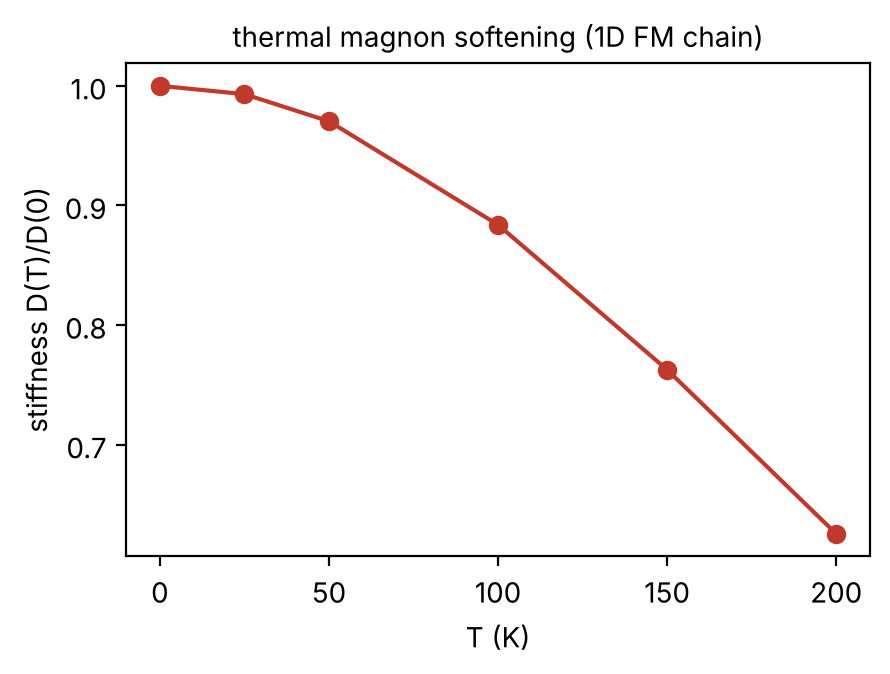

In [3]:
hf0, _ = hf_model("fm", 1.5, -5.0, K=0.3, T=0.0); k = np.array([1.0, 0, 0])
print("T = 0: HF − LSWT =", hf0.spectrum([k])[0][0] - hf0.bare_spectrum([k])[0][0], "meV")
Ts = [0, 25, 50, 100, 150, 200]; ratio = []
for T in Ts:
    hf, _ = hf_model("fm", 1.5, -5.0, K=0.3, T=T)
    ks = hf.kgrid((400, 1, 1)); e0 = np.array([hf.bare_spectrum([q])[0][0] for q in ks])
    c = np.mean((1 - np.cos(a * ks[:, 0])) * _bose(e0, T)); E0 = hf.bare_spectrum([k])[0][0]
    E = hf.spectrum([k])[0][0]; ratio.append((E - 0.9) / (E0 - 0.9))
    print(f"T = {T:4d} K: ε(k) HF = {E:8.4f}  Dyson = {0.9 + (E0 - 0.9) * (1 - c / 1.5):8.4f}  LSWT = {E0:.4f} meV")
fig, ax = plt.subplots(figsize=(4.8, 3.2)); ax.plot(Ts, ratio, "o-", color="#c0392b")
ax.set_xlabel("T (K)"); ax.set_ylabel("stiffness D(T)/D(0)"); ax.set_title("thermal magnon softening (1D FM chain)", fontsize=10)

## A2. Antiferromagnet: zero-point fluctuations stiffen the spin waves (Oguchi)

At $T=0$ the HF correction rescales the AFM spectrum by $Z=1+r/2S$, $r=1-\frac1N\sum_k\sqrt{1-\gamma_k^2}$:
$r=1-2/\pi=0.3634$ (chain), $0.1579$ (square lattice; $Z_c=1.158$ for $S=\frac12$).

In [4]:
for S in (0.5, 1.0, 2.5):
    hf, _ = hf_model("afm", S, 3.0, grid=(800, 1, 1)); kk = np.array([0.3, 0, 0])
    print(f"chain  S = {S}: Z = {hf.spectrum([kk])[0][0] / hf.bare_spectrum([kk])[0][0]:.6f}   1 + (1 − 2/π)/2S = {1 + (1 - 2/np.pi)/(2*S):.6f}")
hf, lat = hf_model("square", 0.5, 1.0, grid=(40, 40, 1))
for kf in ([0.05, 0.02, 0], [0.31, 0, 0]):
    kk = np.array(kf) @ (2 * np.pi * np.linalg.inv(lat).T)
    print(f"square S = 1/2, k = {kf}: Z = {hf.spectrum([kk])[0][0] / hf.bare_spectrum([kk])[0][0]:.5f}  (Oguchi 1.15795)")

chain  S = 0.5: Z = 1.363380   1 + (1 − 2/π)/2S = 1.363380


chain  S = 1.0: Z = 1.181690   1 + (1 − 2/π)/2S = 1.181690


chain  S = 2.5: Z = 1.072676   1 + (1 − 2/π)/2S = 1.072676


square S = 1/2, k = [0.05, 0.02, 0]: Z = 1.15794  (Oguchi 1.15795)
square S = 1/2, k = [0.31, 0, 0]: Z = 1.15794  (Oguchi 1.15795)


### Ordered moment
$\langle S^z\rangle=S-\langle a^\dagger a\rangle$. On the square lattice the zero-point reduction is $\approx0.197$ (grid-converged value; the
log-singular BZ sum converges slowly). **In 1D** it diverges logarithmically with the grid — no long-range order, as it must be:

In [5]:
for g in (40, 80):
    hf, _ = hf_model("square", 0.5, 1.0, grid=(g, g, 1)); print(f"square S=1/2, grid {g}²: ⟨S^z⟩ = {hf.sublattice_magnetisation((g, g, 1))[0]:.4f}")
for g in (200, 800, 3200):
    hf, _ = hf_model("afm", 0.5, 3.0, grid=(g, 1, 1)); print(f"chain  S=1/2, grid {g}: ⟨S^z⟩ = {hf.sublattice_magnetisation((g, 1, 1))[0]:.4f}")

square S=1/2, grid 40²: ⟨S^z⟩ = 0.3098


square S=1/2, grid 80²: ⟨S^z⟩ = 0.3066
chain  S=1/2, grid 200: ⟨S^z⟩ = -1.1678


chain  S=1/2, grid 800: ⟨S^z⟩ = -1.6089


chain  S=1/2, grid 3200: ⟨S^z⟩ = -2.0475


## A3. Self-consistent spin-wave theory and its breakdown

`order="sc"` iterates the Hartree–Fock correlations. In the 1D ferromagnet thermal fluctuations grow with $T$; at 200 K there is **no**
self-consistent solution — the spin-wave Hamiltonian becomes unstable (Mermin–Wagner: no 1D order at $T>0$):

In [6]:
for T in (50.0, 100.0, 200.0):
    try:
        h1, _ = hf_model("fm", 1.5, -5.0, K=0.3, T=T); hs, _ = hf_model("fm", 1.5, -5.0, K=0.3, T=T, order="sc")
        print(f"T = {T:5.0f} K: first order {h1.spectrum([k])[0][0]:.4f}, self-consistent {hs.spectrum([k])[0][0]:.4f} meV ({hs.iterations} iterations)")
    except ValueError as err:
        print(f"T = {T:5.0f} K: {str(err)[:150]}...")

T =    50 K: first order 29.8654, self-consistent 29.8177 meV (29 iterations)


T =   100 K: first order 27.2816, self-consistent 26.2458 meV (45 iterations)


T =   200 K: spin-wave Hamiltonian not positive definite at k = [0.2958 0.     0.    ] — the Hartree–Fock renormalisation destroys the order (fluctuations too stro...


## B1. Self-energies: $-2\,\mathrm{Im}\,\Sigma(\omega_0)$ is the golden rule

With the same Lorentzian broadening the identity is exact; the real part is new information (energy shift):

In [7]:
vx = MagnonPhononVertex(fm_chain_mp(1.0)["model"])
e0, W, E = vx.magnon_poles(X, 0, T=300, grid=(300, 1, 1))
s0 = vx.self_energy(W, E, [e0], 0.05)[0]
g = vx.magnon_linewidth(X, T=300, grid=(300, 1, 1), sigma=0.05, broadening="lorentz")["gamma"][0]
print(f"magnon at X (dJ/dr = 1 meV/Å): −2 Im Σ = {-2*s0.imag:.6f}  golden rule = {g:.6f} meV;  Re Σ = {s0.real:+.4f} meV")
ws = np.linspace(e0 - 15, e0 + 15, 6001); A = vx.spectral(e0, vx.self_energy(W, E, ws, 0.05), ws, 1e-3)
print("∫A dω =", round(np.trapezoid(A, ws), 4), ";  peak at", round(ws[np.argmax(A)], 3), "meV (bare", round(e0, 3), ")")

magnon at X (dJ/dr = 1 meV/Å): −2 Im Σ = 0.181466  golden rule = 0.181466 meV;  Re Σ = -0.0438 meV
∫A dω = 1.0 ;  peak at 20.57 meV (bare 20.6 )


## B2. Strong coupling: the golden rule breaks down

With $\mathrm dJ/\mathrm dr=3$ meV/Å the zone-boundary magnon sits inside the phonon-emission continuum; Re Σ has a square-root
singularity at the continuum edge (1D) and a **sharp split-off state** appears above it, carrying only part of the weight:

dJ/dr = 1.0: peak 20.570 meV (bare 20.60); weight within ±1 meV of the peak 0.929


dJ/dr = 3.0: peak 23.165 meV (bare 20.60); weight within ±1 meV of the peak 0.221


(10.0, 27.0)

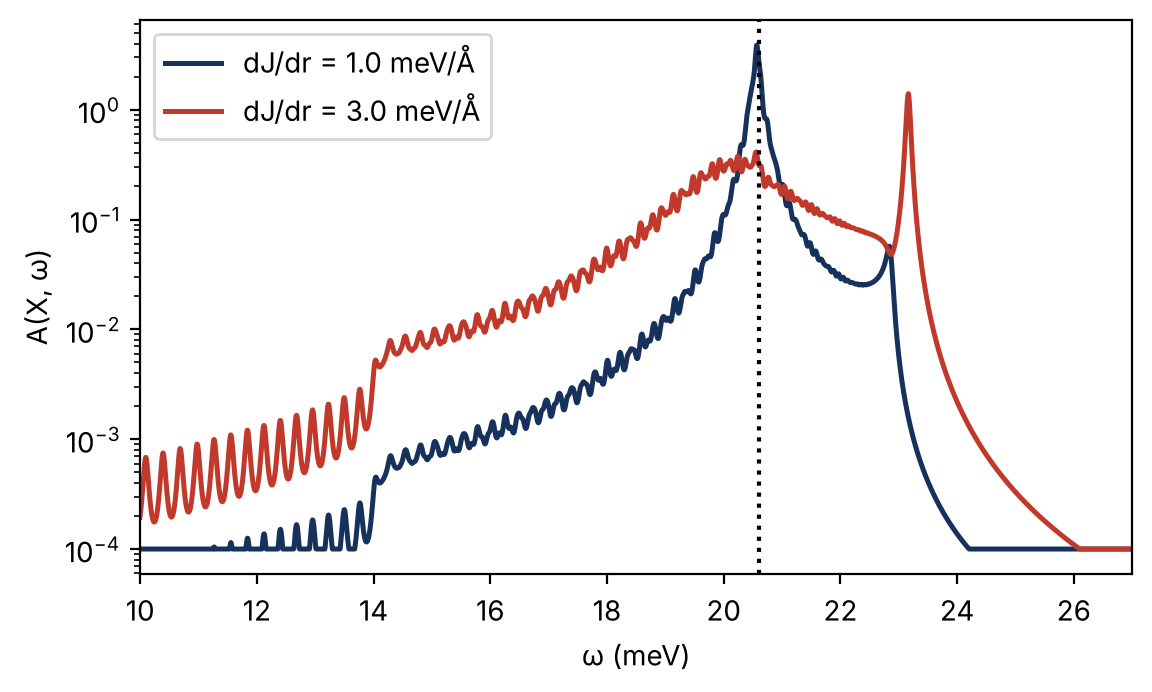

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for dj, c in ((1.0, "#16325c"), (3.0, "#c0392b")):
    v = MagnonPhononVertex(fm_chain_mp(dj)["model"]); e0, W, E = v.magnon_poles(X, 0, T=300, grid=(300, 1, 1))
    A = v.spectral(e0, v.self_energy(W, E, ws, 0.05), ws, 1e-3); i = int(np.argmax(A))
    print(f"dJ/dr = {dj}: peak {ws[i]:.3f} meV (bare {e0:.2f}); weight within ±1 meV of the peak {np.trapezoid(A[abs(ws-ws[i])<1], ws[abs(ws-ws[i])<1]):.3f}")
    ax.semilogy(ws, np.clip(A, 1e-4, None), color=c, lw=1.8, label=f"dJ/dr = {dj} meV/Å")
ax.axvline(e0, ls=":", color="k"); ax.set_xlabel("ω (meV)"); ax.set_ylabel("A(X, ω)"); ax.legend(); ax.set_xlim(10, 27)

## B3. Spectral map along Γ–X

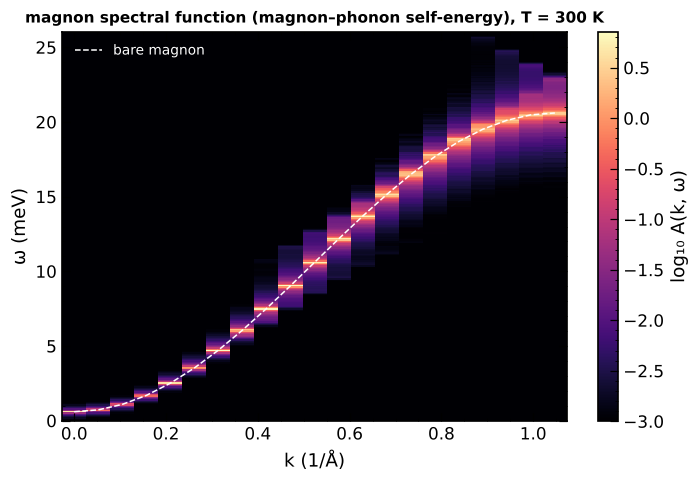

In [9]:
r = fm_chain_mp(1.0)
sm = magnon_spectral_map(r["model"], r["q"], r["x"], np.linspace(0, 26, 300), T=300.0, grid=(200, 1, 1), eta=0.1, every=3)
plot_spectral_map(sm);

## Command line
```bash
cd examples/vasp/Square_AFM_HF   && symphase magnons --J 1.0 --rmax 3.1 --spin 0.5 --hf 0 --hf-grid 40 40          # Oguchi
cd examples/vasp/AFM_chain_HF    && symphase magnons --J 3.0 --rmax 3.1 --spin 1 --hf 0 --hf-grid 800
symphase magnons ... --hf 100 --hf-order sc                                                       # self-consistent
cd examples/vasp/MagnonPhonon_FM_chain && symphase magnons --J -5 --K 0.3 --K-axis 0 0 1 --spin 1 --rmax 3.1 \
        --phonons springs.dat --dJdr 1 --linewidth 300 --spectral
```
Limits: exact to $1/S$ for collinear magnets; cubic magnon terms of non-collinear orders and second-order four-magnon damping are not
included. Continue with **23_quiz_magnon_interactions.ipynb**.